# CS577 Phase 2: Group 6 (Aaron Timbang, Sergio Fernandez Donneys)

## README
1. Original research question: Can a game's genre and platform be used to predict its sales performance in the North American market, among platforms with a substantial number of released titles?
2. Can a game's genre and platform be used to predict its North American sales, among
VGChartz-tracked titles released through 2024 on platforms with at least 100 tracked titles?
3. Description of datasets: df1 1970-2024 scope includes titles, platforms, NA_Sales, Total_Sales etc
                         df2 2016 scope includes titles, platforms, NA_Salesm Total_Sales, Ratings etc.
4. Second dataset: https://www.kaggle.com/datasets/sidtwr/videogames-sales-dataset?resource=download
5. Cleaning steps: 1. Dropped null values
                2. Converted str "NA_Sales" data types into numerical valuess
                3. Dropped duplicate rows and keeping first ["Title]["Platform] key
                4. Dropped NA_Sales labeled "$-"
6. Final dataset shape: (12348, 12)
7. AI use disclosure: Claude for 2F "how to clean data"

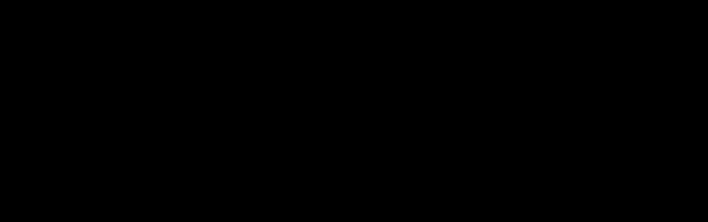
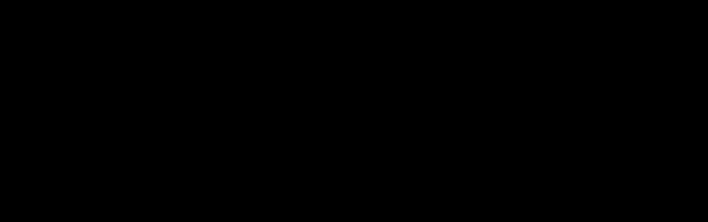

## Part 0: Proposal Revisit
1. We changed our research question (narrowed its scope). We did not change our dataset.
2. Our decision to alter our research question was due to several factors, those being scope, faithfulness, and temporality. Our dataset only encompasses tracked data from VGChartz so the entire game market was not covered in our dataset. Tracked sales stopped around 2024 so we decided to set that as another parameter in our question. For faithfulness, many titles/platforms did not include sales in their data so we had to drop any rows without sales. Our original question tried to predict the entire NA market but that is not feasible with our current dataset.
3. Can a game's genre and platform be used to predict its North American sales, among
VGChartz-tracked titles released through 2024 on platforms with at least 100 tracked titles?
4. We drop the all encompassing North American market and narrowed it down to sales tracked by VGChartz which is still a renowned video game website. We also removed choosing two specific genres to include in our question and instead use all available genres to predict and analyze sales.
5. We gained a better scope and cleaner data to work with.

## Part 1: Dataset Preparation and Joins


### 1A. Choose Your Second Dataset

In [1]:
# New package: pip install cufflinks "plotly<6"
import numpy as np
import pandas as pd
import cufflinks as cf

np.set_printoptions(legacy="1.25")
cf.go_offline()
pd.set_option("display.max_columns", 500)

In [2]:
# load csv's
df1 = pd.read_csv("VideoGames_Sales.csv")
df2 = pd.read_csv("Video_Games_Sales_as_at_22_Dec_2016.csv")

# Sanity check remove spaces around column "Name"
df1.columns = df1.columns.str.strip()
df2["Name"] = df2["Name"].str.strip()

# C X R
print("Initial dataset:", df1.shape)
print("Second dataset:", df2.shape)

# Visual column names for both datasets
print("Initial dataset:", list(df1.columns))
print("Second dataset:", list(df2.columns))


Initial dataset: (64016, 12)
Second dataset: (16719, 16)
Initial dataset: ['Title', 'Platform', 'Genre', 'Publisher', 'Developer', 'Critic_Score', 'Total_Sales', 'NA_Sales', 'JP_Sales', 'PAL_Sales', 'Other_Sales', 'Release_Date']
Second dataset: ['Name', 'Platform', 'Year_of_Release', 'Genre', 'Publisher', 'NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales', 'Critic_Score', 'Critic_Count', 'User_Score', 'User_Count', 'Developer', 'Rating']


### 1B. Merge Requirements

In [3]:
# Granularity check
print("df1 'Title' unique?", df1["Title"].is_unique)
print("df2 'Name' unique?", df2["Name"].is_unique)

# Join key unique
print("df1 duplicates (title, platform) pairs:", df1.duplicated(subset=["Title", "Platform"]).sum())
print("df2 duplicates (name, platform) pairs:", df2.duplicated(subset=["Name", "Platform"]).sum())

dupes = df2[df2.duplicated(subset=["Name", "Platform"])]

df1 'Title' unique? False
df2 'Name' unique? False
df1 duplicates (title, platform) pairs: 225
df2 duplicates (name, platform) pairs: 5


In [4]:
df2Small = (df2[["Name", "Platform", "Rating", "User_Score", "User_Count"]].rename(columns={"Name": "Title"}))
rawMerge = pd.merge(df1, df2Small, how="left", on=["Title", "Platform"],indicator =True)
print(rawMerge.shape)
print(rawMerge["_merge"].value_counts())

(64019, 16)
_merge
left_only     48078
both          15941
right_only        0
Name: count, dtype: int64


In [5]:
df2Unique = (df2Small.dropna(subset=["Title"]).drop_duplicates(subset=["Title", "Platform"], keep = False))
print("df2 rows:", len(df2Small), len(df2Unique))

merged = pd.merge(df1, df2Unique, how="left", on=["Title", "Platform"], indicator=True, validate="many_to_one")

print(merged.shape)
print(merged["_merge"].value_counts())

merged = merged.drop(columns=["_merge"])
print("Final merged shape:", merged.shape)



df2 rows: 16719 16709
(64016, 16)
_merge
left_only     48081
both          15935
right_only        0
Name: count, dtype: int64
Final merged shape: (64016, 15)


1. We used a "2016 Video Games Sales" dataset from Kaggle to supplement our initial one with more titles and platforms
2. The columns we joined were: "Title + Platform" to make this work we renamed the column "Name" in df2 and merged our key pair to df1.
3. Number of rows in each dataset before the join: [64,016, 16,719]
4. Number of row in the merged result: [64,019]
5. Granularity: Both datasets are one row per game per platform, we did not need to convert any data we simply renamed "Name" -> "Title" to make the two line up.
6. Our "Title + Plaform" key was not unique is each table with 225 in df1 and 5 in df2. A non-unique key in this instance would ruin our row count during the join and cause duplicates.

### 1C. Final Working Dataset Requirements: using our initial dataset (df1)

In [6]:
print(df1.shape)
df1.info()
df1.describe()

(64016, 12)
<class 'pandas.DataFrame'>
RangeIndex: 64016 entries, 0 to 64015
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Title         64016 non-null  str    
 1   Platform      64016 non-null  str    
 2   Genre         64016 non-null  str    
 3   Publisher     64016 non-null  str    
 4   Developer     63999 non-null  str    
 5   Critic_Score  6678 non-null   float64
 6   Total_Sales   18922 non-null  str    
 7   NA_Sales      12637 non-null  str    
 8   JP_Sales      6726 non-null   str    
 9   PAL_Sales     12824 non-null  str    
 10  Other_Sales   15128 non-null  str    
 11  Release_Date  56965 non-null  str    
dtypes: float64(1), str(11)
memory usage: 5.9 MB


,Critic_Score
count,6678.000000
mean,7.220440
std,1.457066
min,1.000000
25%,6.400000
50%,7.500000
75%,8.300000
max,10.000000


### 1D. Column Selection and Classification

| Column Name | dtype | Variable Type | Justification | Relevance to Question |
| --- | --- |---------------| --- | --- |
| NA_Sales | str | Quant. Cont   | Represents price, can take any decimal value(not converted from str to float yet) | This is the variable we are trying to predict in our question
| Total_Sales | str | Quant. Cont   | Represents price, can take any decimal value(not converted from str to float yet) | Indicator of whether games that sell well in NA also do well gloablly
| Genre | str | Qual. Nominal | Categories such as Action or Shooter with no natural order | One of our two predictors |
| Platform | str | Qual. Nominal | Again another category with no value such as PS4, XBOX | Our seecond predictor |
| Publisher | str | Qual. Nominal | Categorical value like Sony or Nintendo | Larger publishers may influences sales across our two variables of genre and platform |


## Part 2: Key Data Properties Audit

### 2A. Structure: What is the "shape" of the data file?
1. The data arrived in a .csv file. We did not have to un-nest or parse anything to make it rectangular
2. The primary key we are using is a set of columns (Title + Platform). Code provided above where each row is able to be identified however there are 225 duplicates within the dataset.
3. Currently our main targets fields of NA_Sales are stored as strings; we will need to convert those into numerical values.

### 2B. Granularity: How fine or coarse is each record?
1. Each row represents one game on one platform.
2. Our data is not aggregated. Moreover, our second dataset follows this same structure where each row identifies one row per game per platform with individual sales.

### 2C. Scope: How complete is the data?
1. Our data covers the majority of game releases from the 1970's up to 2024, this includes NA_Sales which our question is about.
2. Our sampling frame includes almost all video game releases in that timeframe but only uses VGChartz for relevant data; this may differ from our population of interest as numbers may change with our sale collecting platforms.

### 2D. Temporality: How is the data situated in time?

In [7]:
dates = pd.to_datetime(df1["Release_Date"], format="%m/%d/%Y")
print(dates.min())
print(dates.max())


1971-12-03 00:00:00
2024-12-31 00:00:00


1. The date range is from 1971-2024.
2. THe timestamp represents when the game was released.

## 2E. Faithfulness: Do you trust this data?

In [8]:
df1.isnull().sum()

Title               0
Platform            0
Genre               0
Publisher           0
Developer          17
Critic_Score    57338
Total_Sales     45094
NA_Sales        51379
JP_Sales        57290
PAL_Sales       51192
Other_Sales     48888
Release_Date     7051
dtype: int64

1. There are thousands of missing sale values, however we still have the required 1,000 row value target with our current dataset.
2. For duplicates in our key combo we will keep the first occurrence and for null entries for both sales and criticScores they will be dropped.
3. Also we need to convert sales str datatype into numerical values.

## 2F. Clean and Lock In Your Working Dataset

In [9]:
df1Clean = df1.copy()
print("Before cleaning:", df1Clean.shape)

Before cleaning: (64016, 12)


Converting str to numbers and overwriting columns with "$-" ** Used Claude for this I had no clue what to do here

In [10]:
missingBefore = df1Clean['NA_Sales'].isnull().sum()

df1Clean['NA_Sales'] = pd.to_numeric(df1Clean['NA_Sales'].str.replace('$', '', regex=False).str.strip(), errors='coerce')
df1Clean['Total_Sales'] = pd.to_numeric(df1Clean['Total_Sales'].str.replace('$', '', regex=False).str.strip(), errors='coerce')

print('"$-" values turned into NaN:', df1Clean['NA_Sales'].isnull().sum() - missingBefore)

"$-" values turned into NaN: 280


NA_Sales == null prior to cleaning

In [11]:
print(df1Clean.shape)
print(df1Clean["NA_Sales"].isnull().sum())

(64016, 12)
51659


Drop rows with no NA sales

In [12]:
rowsBefore = len(df1Clean)
df1Clean = df1Clean.dropna(subset=["NA_Sales"])
print("rows removed:", rowsBefore - len(df1Clean))

rows removed: 51659


NA_Sales == null after cleaning

In [13]:
print(df1Clean.shape)
print(df1Clean["NA_Sales"].isnull().sum())

(12357, 12)
0


Drop duplicate keys

In [14]:
rowsBefore = len(df1Clean)
df1Clean = df1Clean.drop_duplicates(subset=["Title", "Platform"], keep ="first")
print("rows removed:", rowsBefore - len(df1Clean))

rows removed: 9


Verify rows and save result to phase2_working.csv

In [15]:
print("after cleaning:", df1Clean.shape)
print("missing NA_Sales:", df1Clean["NA_Sales"].isnull().sum())
print("duplicate keys:", df1Clean.duplicated(subset=["Title", "Platform"]).sum())
df1Clean.to_csv("phase2_working.csv", index = False)

after cleaning: (12348, 12)
missing NA_Sales: 0
duplicate keys: 0


## Part 3: Faithfulness Stress Test

In [16]:
df = pd.read_csv("phase2_working.csv")
dfTest = df.sample(50, random_state=577).copy()
print(dfTest.shape)

(50, 12)


3A & 3B. Choose Your Corruption Pathways with detect and document

Category 1: Non-Unique Key

In [17]:
dfBroken = pd.merge(dfTest, dfTest[["Platform"]], on = "Platform")

print("Rows before", dfTest.shape[0], "Rows after:", dfBroken.shape[0])
print("Duplicated Title + Platform after join:", dfBroken.duplicated(subset=["Title", "Platform"]).sum())

Rows before 50 Rows after: 306
Duplicated Title + Platform after join: 256


Documentation:
We took a 50-raw random sample of our cleaned dataset and merged it with its own "Platform". Since "Platform is not a unique key the row count grew from 50 to 306, adding 256 rows that do not represent real games. Each game was duplicated for every other game in the sample tha shared its platform. We detect it by comparing to row counts before and after the merge. The ouput shows 50 rows before and 306 after, even though no new games were added. This violates granularity and structure, our dataset should have one row per game per platform, but after the join, a single game appears multiple times. If this issue had gone uncheck, every count in Part 6 would be inflated, and platforms with more titles would be multiplied the most, which would have distorted the visualization of the data.

Category 2: Format Conversion

In [18]:
dfTest2 = df.copy()
dfTest2.to_csv("Encoding_Test.csv", index = False)
dfTestBroken = pd.read_csv("Encoding_Test.csv", encoding = "latin-1")

print("shape before:", dfTest2.shape, "after:", dfTestBroken.shape)
print('dtypes match:', (dfTest2.dtypes == dfTestBroken.dtypes).all())

changes = dfTest2.compare(dfTestBroken)
print('rows changed:', len(changes))
print('columns affected:', changes.columns.get_level_values(0).unique().tolist())
changes.head()

shape before: (12348, 12) after: (12348, 12)
dtypes match: True
rows changed: 64
columns affected: ['Title', 'Developer']


Title  \
                                                   self   
750                                                 NaN   
830                                                 NaN   
1224  Pok?©mon Mystery Dungeon: Red Rescue Team (US ...   
1415                                  Pok?©mon Conquest   
1646                                                NaN   

                                                         \
                                                  other   
750                                                 NaN   
830                                                 NaN   
1224  Pok?Â©mon Mystery Dungeon: Red Rescue Team (US...   
1415                                 Pok?Â©mon Conquest   
1646                                                NaN   

                      Developer                                   
                           self                            other  
750                 EA¬†Tiburon                   EAÂ¬â Tiburon  
830                  EA¬†Canada                    EAÂ¬â Canada  
1224                        NaN                              NaN  
1415                        NaN                              NaN  
1646  Black¬†Ops¬†Entertainment  BlackÂ¬â OpsÂ¬â Entertainment

Documentation:
We save a copy of our cleaned dataset to a CSV file using the defualt UTF-8 encoding, then reloaded it using latin-1 encoding. This simulates opening a file with the wrong encoding, which is more common that we think when the data passes through different tools or operating systems. When doing this 64 rows changed across the "Title" and "Developer" columns. Special characters were replaced with garbled text, as shown in the ouput above. The shape and the columns data types did not change in the process. The issue was detected when we use 'dfTest2.compare(dfTestBroken)', which reported 64 rows changed across two columns. This issue violates the faithfulness principle, because the values no longer match the original data, it also violates the structure of the dataset since it comes from how the text is encoded in the file. If we did not discover this issue, affected titles would no longer match between databases. If this happens to a categorical column, on publisher could ended up split into two different categories, which could eventually distort group counts and averages.

## Part 4: Pandas Query

For genres with at least 100 titles, which have the highest average NA sale?

In [19]:
result = (df.groupby('Genre')
            .agg(titles=('NA_Sales', 'size'), avg_na_sales=('NA_Sales', 'mean'))
            .query('titles >= 100')
            .sort_values('avg_na_sales', ascending=False))
print(result)

                  titles  avg_na_sales
Genre                                 
Shooter             1197      0.441328
Sports              1933      0.313859
Action-Adventure     211      0.308483
Fighting             576      0.302014
Action              2081      0.283051
Misc                1182      0.250135
Platform             794      0.236725
Racing              1175      0.229549
Simulation           671      0.227779
Role-Playing         775      0.221510
Adventure            797      0.197315
Puzzle               455      0.141429
Strategy             346      0.136012


The query is answering for all our genres with at least 100 title, which have the highest average NA sales? 'Groupby' splits the games by genre, "agg" then counts the titles and averages "NA_Sales" in each genre. Query removes genres with our condition of >= 100. Sort_values ranks them from highest to lowest average (ascending = False). The output shows that shooters have the greatest average sale and strategy games have the lowest of 0.136. This connects directly with our overall research question since it supports our hypothesis of certain genres being better sellers in the NA market.

## Part 5: Correlation Analysis

In [20]:
correlation = df["NA_Sales"].corr(df["Total_Sales"])
print(f"The correlation between NA_sales and Total_sales is: {correlation: .4f}")

The correlation between NA_sales and Total_sales is:  0.9139


The correlation we received from calculating NA_Sales with Total_Sales was 0.9139. This numeric value represents a positive relationship. This suggests that games that sell well in NA will almost always sell globally. One caveat is that the NA market encompasses alot of game sales so that could have a direct influence on the numbers as our dataset only considers Japan & PAL as the other markets. I don't think any faithfulness issues followed our clean dataframe as we dropped null values and "$-" entries.

## Parts 6 & 7: Exploratory Data Analysis (EDA Questions)

Required Visualization 1: Category Counts (Bar Chart)

### Which platforms have the most tracked titles?

In [21]:
platformCounts = df["Platform"].value_counts()
platformCounts.iplot(kind="bar", title="Number of Titles per Platform Counts", xTitle = "Platform", yTitle = "Number of Titles")

We used 'value_counts()' on the Platform column and display the results. The chart shows that the PS2 has the most tracked titles with roughly 1,550, followed closely by the Nintendo DS, while 19platforms have at least 100 titles and the remaining ten have a handful each. Platforms with fewer titles cannot support reliable conclusions about North American sales, which is why our research question is limited to platforms with at least 100 tracked titles. This uneven coverage also refelcts the scope gap identifed in Part 2, sinve VGChartz tracked some console generations far more heavily than older platforms.

Required Visualization 2: Grouped Aggregation (Bar Chart)

### Among platforms with at least 100 tracked titles, which platforms have the highest average NA sales?

In [25]:
counts = df["Platform"].value_counts()
bigPlatforms = counts[counts >= 100].index

avgByPlatform = (df[df["Platform"].isin(bigPlatforms)]).groupby("Platform")["NA_Sales"].mean().sort_values(ascending = False)

avgByPlatform.iplot(kind = "bar", title = "Average NA Sales by Platform (100+ titles)", xTitle = "Platform", yTitle = "Average NA Sales (mil)")

We used 'isin()' to keep only platforms with at least 100 tracked titles, then used 'groupby()' and 'mean()' to calculate the average NA sales per platform and display the results. The Atari 2600 has the highest average around 0.56 million units per title, followed by the Xbox 360 and PS3, while handhelds such as the 3DS and PS Vita, has the lowest averages. The variation of more than 0.4 million units between the highest and lowest platforms suggest that the platform has a meaningful relationshipwith NA sales, which supports using it as an indicator in our research question.

Required Visualization 3: Distribution (Histogram)

### Is the distribution of NA sales symmetric or skewed?

In [28]:
df['NA_Sales'].iplot(kind='hist', bins=30, title='Distribution of NA Sales',
                     xTitle='NA Sales (millions)', yTitle='Number of Titles')

We plotted the NA sales column as a histogram with 30 bins. The distribution is heavely right-skewed: around 10,700 of our 12,348 titles sold fewwer than 0.5 million units in North America, while a small number of outliers extend past the 8 million mark. This means a few blockbuster such as Call of Duty and GTA V pull the average in the upward direction.

Required Visualization 4: Trend or Top-N Comparison

### Which titles sold the most in North America?

In [30]:
top10 = df.sort_values('NA_Sales', ascending=False).head(10).copy()
top10['Label'] = top10['Title'] + ' (' + top10['Platform'] + ')'

top10.set_index('Label')['NA_Sales'].iplot(kind='bar', title='Top 10 Titles by NA Sales',
                                           xTitle='Title (Platform)', yTitle='NA Sales (millions)')

We sorted the dataset by 'NA_Sales' in descending order, took the top 10 rows and displayed the results, labeling each bar with its title and platform. The top 1- titles comes from the three franchises, Call of Duty, Grand Theft Auto, and Halo. Eight of the ten titles are on the Xbox 360 and the other two on the PS2, all of them belonging to the shooter and action genres, which directly supports our research question's premise that genre and platform are related to NA sales. No tiles from newer platforms such as PS4, Xbox One, or Switch appear in the top 10, which may refelct a temporality issue, since VGCharts tracks physical sales and digital sales became a larger share of the market for newer platforms.